In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['font.family'] = 'Liberation Sans'
rcParams['font.size'] = 12
rcParams['figure.autolayout'] = True
rcParams["savefig.bbox"] = 'tight'
rcParams["savefig.format"] = 'png'
rcParams["savefig.dpi"] = 300
rcParams["grid.linestyle"] = '--'

# from matplotlib_inline import backend_inline
# backend_inline.set_matplotlib_formats('svg')

In [ ]:
import os
import torch
import h5py
from glob import glob
import pandas as pd

import NbDasUtils as utils
from NbDas import DasData 

In [5]:
%matplotlib inline

## Read DAS Strain rate H5 file

In [6]:
h5_filepath = "./strainrate/Route9_SR5m_GL5m_SV5m_StrainRate_20220906T103239+0900_93.h5"
h5_file = h5py.File(h5_filepath, "r")

print("Reading DAS data from HDF5 file: ", h5_filepath)
(
    das_data,
    spatial_sampling_interval,
    time_sampling_interval,
    time_series,
    dist_series,
) = utils.read_h5(h5_file)

# apply highpass filter to remove low frequency noise
print("Applying highpass filter...")
das_data = utils.sos_highpass_filter(das_data, 3, cutf=0.5, fs=1/time_sampling_interval)

# cut time from 20s to 40s
das_data, time_series = utils.crop_das_time_range(das_data, time_series, (25, 35))
# das_data, dist_series = utils.crop_das_distance_range(das_data, dist_series, (0, 30000))

das_data = DasData(das_data, spatial_sampling_interval, time_sampling_interval, dist_series, time_series)

Reading DAS data from HDF5 file:  ./strainrate/Route9_SR5m_GL5m_SV5m_StrainRate_20220906T103239+0900_93.h5
DAS data shape: (30000, 10149)
Applying highpass filter...


In [7]:
# save the preprocessed DAS data to a new HDF5 file
new_file_name = "Route9_SR5m_GL5m_SV_StrainRate_T25to35s.h5"
output_h5_filepath = "./strainrate/" + new_file_name
print("Saving preprocessed DAS data to HDF5 file: ", output_h5_filepath)

new_h5_file = h5py.File(output_h5_filepath, "w")

dset_write = new_h5_file.create_dataset("Acoustic", data=das_data.data)

# copy attributes
for attr in h5_file["Acoustic"].attrs:
    dset_write.attrs[attr] = h5_file["Acoustic"].attrs[attr]

new_h5_file.close()
h5_file.close()

Saving preprocessed DAS data to HDF5 file:  ./strainrate/Route9_SR5m_GL5m_SV_StrainRate_T25to35s.h5


In [8]:
1/time_sampling_interval

np.float32(499.99997)

Time downsample factor:  1
Distance downsample factor:  3


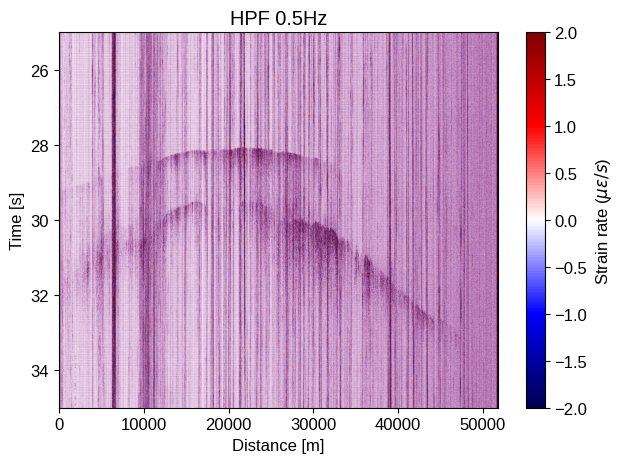

In [9]:
das_data.plot_data(cmap="seismic", title="HPF 0.5Hz", vmin=-2, vmax=2)
plt.grid(False)

## Run PhaseNet-DAS

In [10]:
# Write input file to files.txt
with open("files.txt", "w") as f:
    f.write(f"strainrate/{new_file_name}\n")

In [15]:
ngpu = torch.cuda.device_count()
base_cmd = "../predict.py --model phasenet_das --data_list=files.txt  --data_path ./strainrate --result_path ./results --format=h5  --batch_size 1 --workers 0"

In [16]:
if ngpu == 0:
    cmd = f"python {base_cmd} --device cpu --system neubrex"
elif ngpu == 1:
    cmd = f"python {base_cmd} --system neubrex"
else:
    cmd = f"torchrun --nproc_per_node {ngpu} {base_cmd} --system neubrex"

print(cmd)
os.system(cmd)

python ../predict.py --model phasenet_das --data_list=files.txt  --data_path ./strainrate --result_path ./results --format=h5  --batch_size 1 --workers 0 --system neubrex
Not using distributed mode
Namespace(model='phasenet_das', resume='', backbone='unet', phases=['P', 'S'], device='cuda', workers=0, batch_size=1, use_deterministic_algorithms=False, amp=False, world_size=1, dist_url='env://', data_path='./strainrate', data_list='files.txt', hdf5_file=None, prefix='', format='h5', dataset='das', result_path='./results', plot_figure=False, min_prob=0.3, add_polarity=False, add_event=False, sampling_rate=100.0, highpass_filter=0.0, response_path=None, response_xml=None, subdir_level=0, cut_patch=False, nt=20480, nx=5120, resample_time=False, resample_space=False, system='neubrex', location=None, skip_existing=False, distributed=False)


/home/aung/playground/EQNet/.venv/lib/python3.13/site-packages/torch/backends/__init__.py:46: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  self.setter(val)


Total samples: 1 files


Predicting: 100%|██████████| 1/1 [00:23<00:00, 23.39s/it]


0

## Plot results

In [19]:
picks = pd.read_csv(f"results/picks_phasenet_das/" + new_file_name.replace(".h5", ".csv"))
picks.head()

,channel_index,phase_index,phase_time,phase_score,phase_type
0,0,2100,2022-09-06T10:32:34.323+09:00,0.617,P
1,1,2103,2022-09-06T10:32:34.329+09:00,0.660,P
2,2,2105,2022-09-06T10:32:34.333+09:00,0.699,P
3,3,2106,2022-09-06T10:32:34.335+09:00,0.730,P
4,4,2106,2022-09-06T10:32:34.335+09:00,0.746,P


Time downsample factor:  1
Distance downsample factor:  3


Text(32.99999999999999, 0.5, 'Time (s)')

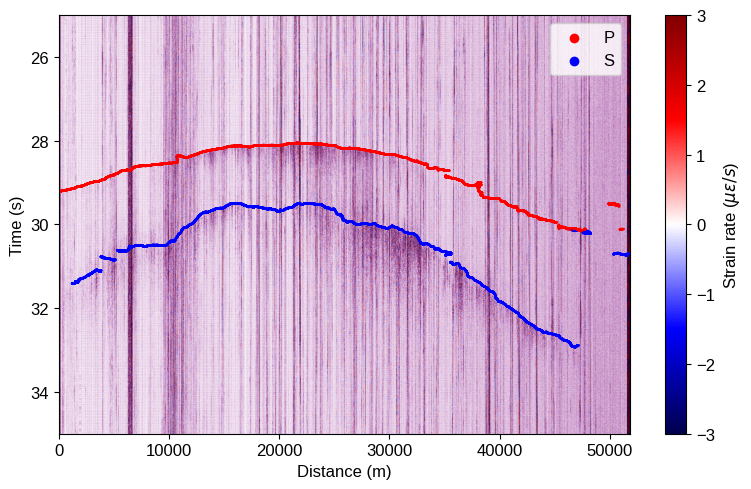

In [20]:
plt.figure(figsize=(8, 5))
das_data.plot_data(cmap="seismic", title="", vmin=-3, vmax=3)
color = picks["phase_type"].map({"P": "r", "S": "b"})
dx = spatial_sampling_interval
dt = time_sampling_interval
plt.scatter(picks["channel_index"].values * dx, picks["phase_index"].values * dt + time_series[0], c=color, s=0.5)
plt.scatter([], [], c="r", label="P")
plt.scatter([], [], c="b", label="S")
plt.legend()
plt.xlabel("Distance (m)")
plt.ylabel("Time (s)")